<div dir="rtl">

# עבודה מסכמת בויזואליזציה: מחקר שיגורים של לוויינים ומשימות בחלל

</div>

<div dir="rtl">
    תחילת עבודה עם מאגר נתונים גדול, אני מוסיף את הספריות הדרושות וטוען את הקבצים לתוך משתנים מסוג פנדה
</div>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_missions = pd.read_csv("Space-Missions-from-1957.csv")

df_satellite = pd.read_excel("UCS-Satellite-Database.xlsx")


<div dir="rtl">
    ניתוח ראשוני של סוגי המידע הקיימים במאגרים וחשיבה על איזה שאלת מחקר אפשר לנסח וגם לענות עליה מנתונים אלו
</div>

In [11]:
print("Missions:")
print(df_missions.columns)
print()
print("Satellite:")
print(df_satellite.columns)

Missions:
Index(['Company Name', 'Country', 'Year', 'Detail', 'Rocket Status',
       'Production Price', 'Mission Status'],
      dtype='str')

Satellite:
Index(['Name of Satellite, Alternate Names',
       'Current Official Name of Satellite', 'Country/Org of UN Registry',
       'Country of Operator/Owner', 'Operator/Owner', 'Users', 'Purpose',
       'Detailed Purpose', 'Class of Orbit', 'Type of Orbit',
       'Longitude of GEO (degrees)', 'Perigee (km)', 'Apogee (km)',
       'Eccentricity', 'Inclination (degrees)', 'Period (minutes)',
       'Launch Mass (kg.)', 'Dry Mass (kg.)', 'Power (watts)',
       'Date of Launch', 'Expected Lifetime (yrs.)', 'Contractor',
       'Country of Contractor', 'Launch Site', 'Launch Vehicle',
       'COSPAR Number', 'NORAD Number', 'Comments', 'Unnamed: 28',
       'Source Used for Orbital Data', 'Source', 'Source.1', 'Source.2',
       'Source.3', 'Source.4', 'Source.5', 'Source.6', 'Unnamed: 37',
       'Unnamed: 38', 'Unnamed: 39', 'Unnamed: 

<div dir="rtl">

#    מתחיל בניקוי המידע שיש במאגר המשימות חלל, יש פה מספר בעיות קריטיות

</div>

<div dir="rtl">
    זה עמודות חסרות משמעות ולכן עלי למחוק אותם
</div>

In [3]:
df_missions = df_missions.drop(columns=["Unnamed: 0.1", "Unnamed: 0"])

<div dir="rtl">
    עכשיו יש עמודה בשם Rocket שלא מתאימה לתיאור האמיתי של העמודה שהוא בכלל עלות הייצור
</div>
<div dir="rtl">
    עכשיו יש עוד כמה עמודות שאני רוצה לשנות להם את השם לצורך נוחות
</div>

In [4]:
df_missions = df_missions.rename(columns={" Rocket": "Production Price"})
df_missions["Production Price"] = df_missions["Production Price"].str.strip()
df_missions["Production Price"] = df_missions["Production Price"].str.replace(",", "")
df_missions["Production Price"] = pd.to_numeric(df_missions["Production Price"])

df_missions = df_missions.rename(columns={"Datum": "Date"})
df_missions = df_missions.rename(columns={"Status Rocket": "Rocket Status"})
df_missions = df_missions.rename(columns={"Status Mission": "Mission Status"})

<div dir="rtl">
    צריך למחוק כפילויות אם יש
</div>

In [5]:
df_missions = df_missions.drop_duplicates()

<div dir="rtl">
    צריך לבדוק מה האחוז של הערכים בכל עמודה בנתונים שהם ריקות 
</div>
<div dir="rtl">
    הבנתי שיש הרבה מאוד חוסרים במחיר הייצור ולכן אדע להשתמש בזה ברגע הנכון ולא להסתמך עליו
</div>

In [6]:
df_missions.isnull().mean() * 100

Company Name         0.000000
Location             0.000000
Date                 0.000000
Detail               0.000000
Rocket Status        0.000000
Production Price    77.723803
Mission Status       0.000000
dtype: float64

<div dir="rtl">
    לפי הראיה האסטרטגית שלי אני חושב שאין צורך במיקום מדוייק ולכן צריך רק את המדינה
</div>

In [7]:
df_missions["Location"] = df_missions["Location"].str.split(",").str[-1].str.strip()
df_missions = df_missions.rename(columns={"Location": "Country"})

<div dir="rtl">
    לצורך נוחות גם צריך לשנות את הצורת כתיבה של הסטטוס אחרת יכול לבלבל בכתיבה
</div>

In [8]:
df_missions["Rocket Status"] = df_missions["Rocket Status"].str.removeprefix("Status")

<div dir="rtl">
    המחקר שלי הוא על מעצמות ויכולות השיגור שלהם ולכן עלי לחלק נכון את הנתונים כי מה שמצויין בנתונים כרגע זה באיזה שטח ולא באמת מי היה אחראי על השיגור
</div> 

In [9]:
country_fix = {
    "Kazakhstan": "Russia",
    "Barents Sea": "Russia",
    "Pacific Ocean": "Multinational",
    "New Mexico": "USA",
    "Gran Canaria": "USA",
    "Pacific Missile Range Facility": "USA",
    "Yellow Sea": "China",
    "Shahrud Missile Test Site": "Iran",
    "Kenya": "Italy",
}
df_missions["Country"] = df_missions["Country"].replace(country_fix)

<div dir="rtl">
    אותי מעניין רק השנה של השיגור לפי זה אני אעשה את הגרפים
</div> 

In [10]:
df_missions["Date"] = pd.to_datetime(df_missions["Date"], format="mixed", utc=True).dt.year
df_missions = df_missions.rename(columns={"Date": "Year"})

<div dir="rtl">

#    עכשיו עוברים לנקות את מאגר הנתונים השני והגדול בהרבה יותר

</div>

<div dir="rtl">
    הרבה מאוד מן העמודות במאגר נתונים כאן מיותרות לחלוטין ואף לא מלאות כמעט
</div> 

In [13]:
df_satellite.isnull().mean() * 100

Name of Satellite, Alternate Names     0.000000
Current Official Name of Satellite     0.000000
Country/Org of UN Registry             0.013228
Country of Operator/Owner              0.000000
Operator/Owner                         0.000000
                                        ...    
Unnamed: 63                           93.584656
Unnamed: 64                           93.584656
Unnamed: 65                           93.584656
Unnamed: 66                           93.558201
Unnamed: 67                           93.584656
Length: 68, dtype: float64

<div dir="rtl">
    ובגלל זה עדיף ליצור ישר טבלה חדשה שתכלול את מה שאני צריך
</div> 

In [15]:
cols = ["NORAD Number", "Current Official Name of Satellite", "Country of Operator/Owner",
        "Operator/Owner", "Users", "Purpose", "Class of Orbit",
        "Launch Mass (kg.)", "Date of Launch"]
df_satellite = df_satellite[cols]

<div dir="rtl">
    חייב להוריד את הכפילויות ולנקות את הסטרינגים מרווחים מיותרים שיפריעו לזיהוי
</div> 

In [ ]:
df_satellite = df_satellite.drop_duplicates()

text_cols = ["Current Official Name of Satellite", "Country of Operator/Owner",
             "Operator/Owner", "Users", "Purpose", "Class of Orbit"]
for col in text_cols:
    df_satellite[col] = df_satellite[col].astype(str).str.strip()

<div dir="rtl">
    ניקוי התאריך ל שנה בלבד 
</div> 

In [ ]:
df_satellite["Date of Launch"] = pd.to_datetime(df_satellite["Date of Launch"], errors="coerce").dt.year
df_satellite = df_satellite.rename(columns={"Date of Launch": "Year"})
df_satellite = df_satellite[df_satellite["Year"] >= 1957]

<div dir="rtl">
    בידוד של המדינה בלבד לפי פורמט שאני רוצה
</div> 

In [29]:
df_satellite = df_satellite.rename(columns={"Country of Operator/Owner": "Country"})
has_slash = df_satellite["Country"].str.contains("/")
df_satellite.loc[has_slash, "Country"] = "Multinational"
df_satellite["Country"] = df_satellite["Country"].replace({"ESA": "Multinational"})

<div dir="rtl">

#   התאמה של כל טבלה בנפרד כדי שיהיה אפשר לאחד אותם

</div>

In [26]:
df_missions["Success"] = (df_missions["Mission Status"] == "Success").astype(int)

missions_by_country = df_missions.groupby("Country").agg(
    Launches=("Success", "count"),
    Success_Rate=("Success", "mean"),
).reset_index()

In [30]:
df_satellite["Military"] = df_satellite["Users"].str.contains("Military").astype(int)

sat_by_country = df_satellite.groupby("Country").agg(
    Satellites=("NORAD Number", "count"),
    Military_Share=("Military", "mean"),
).reset_index()

<div dir="rtl">

#   איחוד הטבלאות לטבלה אחת של מידע

</div>

In [31]:
df_countries = pd.merge(missions_by_country, sat_by_country, on="Country", how="left")
df_countries["Satellites"] = df_countries["Satellites"].fillna(0)
df_countries["Military_Share"] = df_countries["Military_Share"].fillna(0)
df_countries

,Country,Launches,Success_Rate,Satellites,Military_Share
0,Australia,6,0.500000,23.0,0.173913
1,Brazil,3,0.000000,15.0,0.066667
2,China,268,0.906716,618.0,0.254045
3,France,303,0.940594,33.0,0.454545
4,India,76,0.828947,59.0,0.135593
5,Iran,14,0.357143,2.0,1.000000
6,Israel,11,0.818182,29.0,0.413793
7,Italy,9,1.000000,15.0,0.600000
8,Japan,126,0.896825,87.0,0.022989
9,Multinational,36,0.916667,170.0,0.023529


<div dir="rtl">

#   בניית גרפים שיהיה אפשר להסיק מסקנות מהנתונים שהשגתי

</div>

<div dir="rtl">
    גרף המציג כמה שיגורים בצעה כל מדינה
</div>

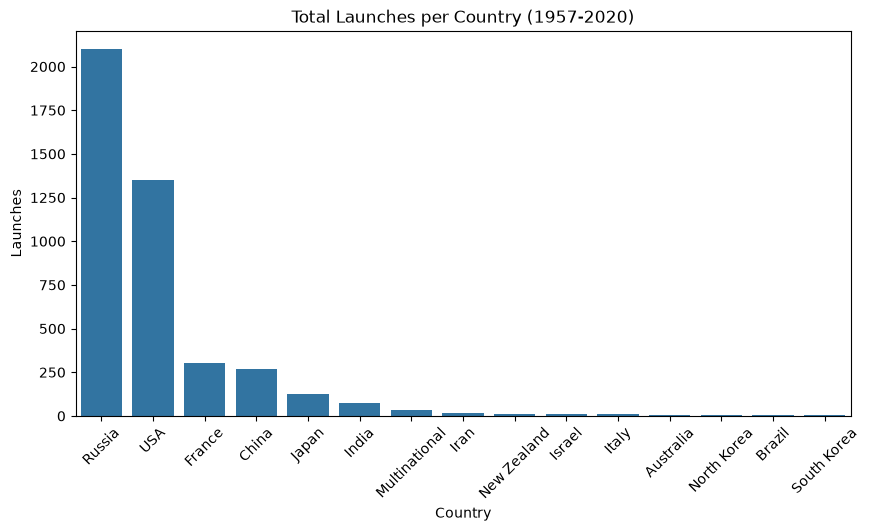

In [40]:
df_sorted = df_countries.sort_values("Launches", ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(data=df_sorted, x="Country", y="Launches")
plt.xticks(rotation=45)
plt.title("Total Launches per Country (1957-2020)")
plt.show()

<div dir="rtl">
    רוסיה וארה״ב רחוקות מאוד מכל השאר בפער ענקי
</div>

<div dir="rtl">
    גרף המציג כמה כל מדינה משקיעה מהמשאבים שלה לצורך מחקר אזרחי או צורך צבאי במשימות חלל
</div>

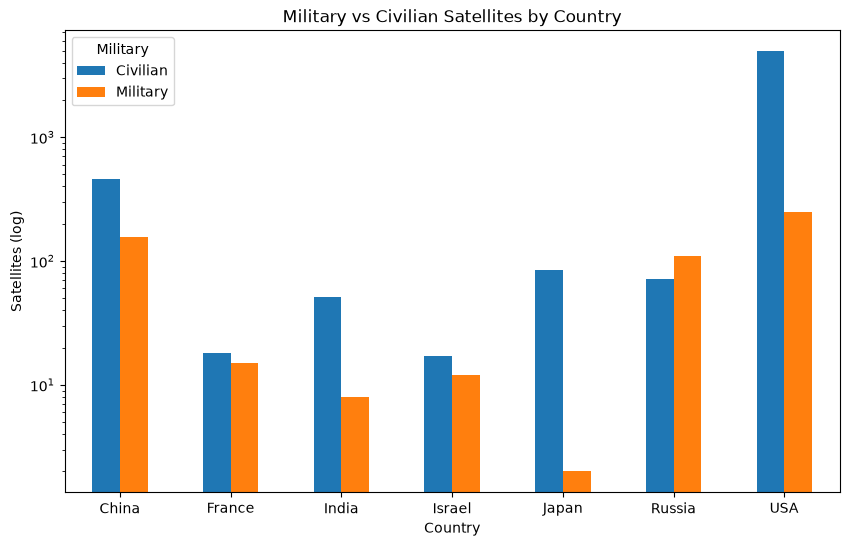

In [41]:
top = ["USA", "Russia", "China", "France", "Japan", "India", "Israel"]
top_sat = df_satellite[df_satellite["Country"].isin(top)]
counts = pd.crosstab(top_sat["Country"], top_sat["Military"].map({1: "Military", 0: "Civilian"}))
counts.plot(kind="bar", stacked=False, figsize=(10, 6))
plt.yscale("log")
plt.title("Military vs Civilian Satellites by Country")
plt.ylabel("Satellites (log)")
plt.xticks(rotation=0)
plt.show()

<div dir="rtl">
    גרך שמציג את כמות הנסיונות פר מדינה להתפתח ביכולת השיגורים שלהם
</div>

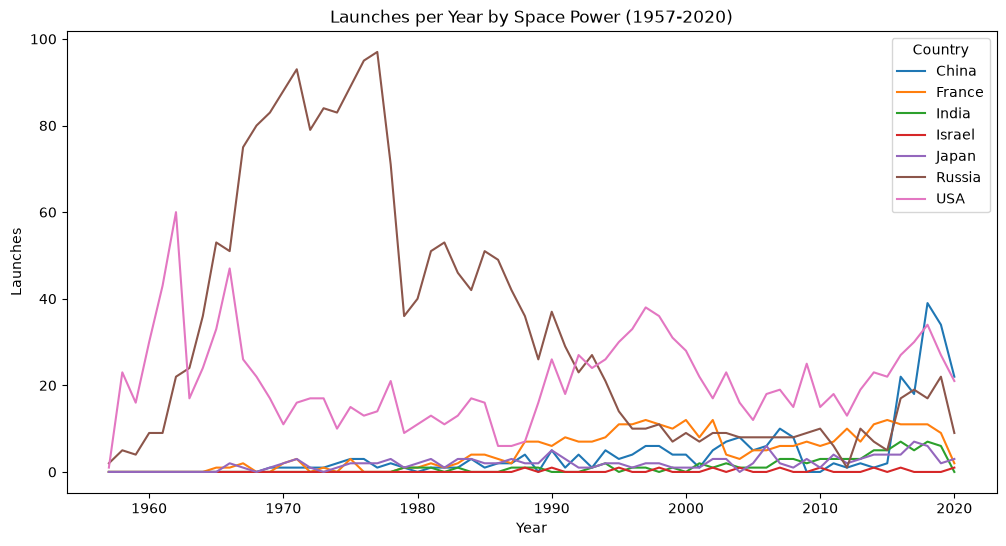

In [43]:
top = ["USA", "Russia", "China", "France", "Japan", "India", "Israel"]
top_missions = df_missions[df_missions["Country"].isin(top)]
yearly = top_missions.groupby(["Year", "Country"]).size().unstack(fill_value=0)
yearly.plot(figsize=(12, 6))
plt.title("Launches per Year by Space Power (1957-2020)")
plt.ylabel("Launches")
plt.show()

<div dir="rtl">
    שיא השליטה של ברית המועצות בשנות ה-70, והירידה החדה אחרי 1991
</div>

<div dir="rtl">

#   בניית מודל KMEANS

</div>

<div dir="rtl">

#   שאלת המחקר: אילו סוגים של מעצמות חלל קיימים, ומה מאפיין כל סוג?

</div>

In [45]:
import numpy as np
from sklearn.preprocessing import StandardScaler

df_model = df_countries[df_countries["Country"] != "Multinational"].copy()

features = ["Launches", "Success_Rate", "Satellites", "Military_Share"]
X = df_model[features].copy()
X["Launches"] = np.log1p(X["Launches"])
X["Satellites"] = np.log1p(X["Satellites"])

X_scaled = StandardScaler().fit_transform(X)

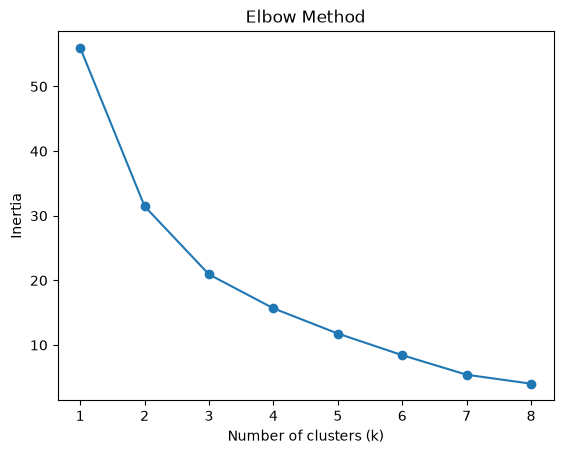

In [46]:
inertias = []
for k in range(1, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.plot(range(1, 9), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [48]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=10)
df_model["Cluster"] = kmeans.fit_predict(X_scaled)

print(df_model.sort_values("Cluster"))
df_model.groupby("Cluster")[features].mean()

        Country  Launches  Success_Rate  Satellites  Military_Share  Cluster
5          Iran        14      0.357143         2.0        1.000000        0
2         China       268      0.906716       618.0        0.254045        1
3        France       303      0.940594        33.0        0.454545        1
4         India        76      0.828947        59.0        0.135593        1
8         Japan       126      0.896825        87.0        0.022989        1
12       Russia      2099      0.911386       181.0        0.607735        1
14          USA      1351      0.879349      5158.0        0.047887        1
0     Australia         6      0.500000        23.0        0.173913        2
1        Brazil         3      0.000000        15.0        0.066667        2
11  North Korea         5      0.400000         0.0        0.000000        2
13  South Korea         3      0.333333        21.0        0.095238        2
6        Israel        11      0.818182        29.0        0.413793        3

,Launches,Success_Rate,Satellites,Military_Share
Cluster,,,,
0,14.000000,0.357143,2.000000,1.000000
1,703.833333,0.893970,1022.666667,0.253799
2,4.250000,0.308333,14.750000,0.083954
3,11.000000,0.888112,15.000000,0.337931


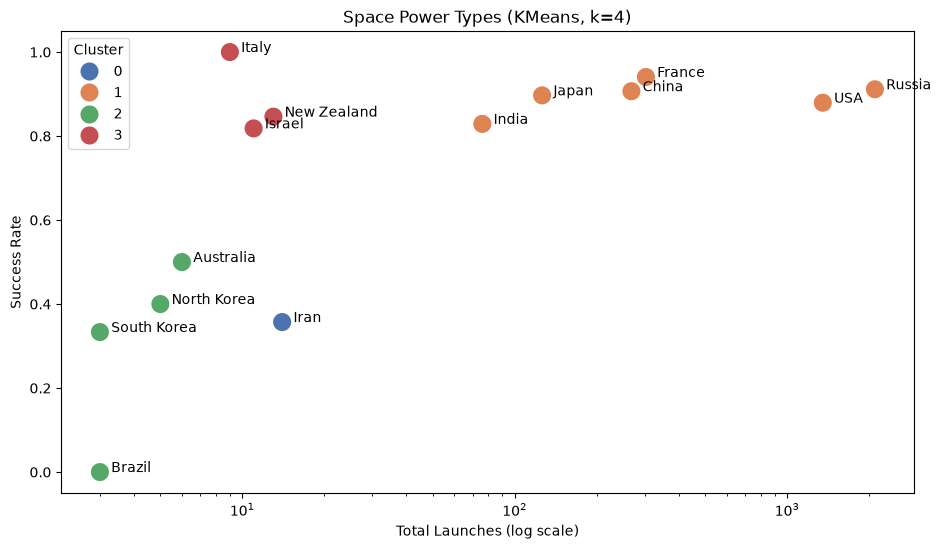

In [49]:
plt.figure(figsize=(11, 6))
sns.scatterplot(data=df_model, x="Launches", y="Success_Rate",
                hue="Cluster", palette="deep", s=200)
for _, row in df_model.iterrows():
    plt.text(row["Launches"] * 1.1, row["Success_Rate"], row["Country"])
plt.xscale("log")
plt.title("Space Power Types (KMeans, k=4)")
plt.xlabel("Total Launches (log scale)")
plt.ylabel("Success Rate")
plt.show()

<div dir="rtl">

## תשובה לשאלת המחקר

**שאלת המחקר:** אילו סוגים של מעצמות חלל קיימים, ומה מאפיין כל סוג?

אלגוריתם KMeans חילק את מדינות החלל ל־4 סוגים:

1. **מעצמות מובילות** (ארה"ב, רוסיה, סין, צרפת, יפן, הודו): מאות עד אלפי שיגורים, אחוז הצלחה של כ־89% ומאות לוויינים פעילים.
2. **שחקניות קטנות ומדויקות** (ישראל, איטליה, ניו זילנד): מעט שיגורים, אבל אחוז הצלחה זהה לזה של המעצמות.
3. **מדינות מתקשות** (ברזיל, אוסטרליה, דרום וצפון קוריאה): מעט שיגורים ואחוז הצלחה של כ־31% בלבד.
4. **מקרה חריג – איראן:** הצלחה נמוכה וכל הלוויינים שלה צבאיים.

**ממצאים נוספים מהגרפים:**
- ברית המועצות שלטה בחלל עד 1991, ואחרי התפרקותה מספר השיגורים שלה ירד בחדות. סין עלתה מאוד בשנים האחרונות.
- לכל מעצמה יש אופי שונה: לרוסיה הכי הרבה לוויינים צבאיים, ואצל ארה"ב רוב הלוויינים מסחריים.
- רוסיה ביצעה הכי הרבה שיגורים בהיסטוריה, אבל לארה"ב יש היום פי 28 לוויינים פעילים. מי ששלט בעבר לא בהכרח שולט היום.

**בדיקת ההשערה:** שיערתי שמדינות שמשגרות יותר מצליחות יותר. ההשערה נכונה ברובה, אבל ישראל, איטליה וניו זילנד הן יוצאות דופן: הן מצליחות מאוד גם עם מעט שיגורים.

**מגבלות המחקר:**
- נתוני השיגורים מסתיימים באוגוסט 2020, ונתוני הלוויינים כוללים רק לוויינים שפעילים היום.
- איראן נמצאת לבד בקבוצה, כי אחוז הלוויינים הצבאיים שלה מבוסס על 2 לוויינים בלבד.

</div>